# Remote Entanglement

Python companion to the AMO Toolkit page [Remote Entanglement](https://amotoolkit.com/pages/remote-entanglement.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/remote-entanglement.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Heralded entanglement rate
Per attempt, each atom's photon reaches a detector with probability $\eta = \eta_\mathrm{coll}\,\eta_\mathrm{fibre}\,T\,\eta_\mathrm{det}$, with free-space collection $(1-\sqrt{1-\mathrm{NA}^2})/2$ (or β·0.85 with a cavity of Purcell factor F, β = (F−1)/F) and fibre transmission $T = 10^{-\alpha L/10}$.

* **two-photon** (Barrett–Kok) heralding: $p = \eta^2/2$, high fidelity
* **single-photon** (Cabrillo) heralding with excitation ε: $p \approx 2\varepsilon\eta$, fidelity ≈ 1 − ε

The attempt rate is capped by the herald round trip 2L/v with v ≈ c/1.47 in fibre.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def link(NA=0.5, fibre=0.65, det=0.85, f_rep=1e6, L_km=0.01, alpha_dB_km=0.18, scheme="two-photon", purcell=1.0, eps=0.05):
    eta_coll = (1 - np.sqrt(1 - NA**2)) / 2 if purcell == 1 else (purcell - 1) / purcell * 0.85
    T = 10 ** (-alpha_dB_km * L_km / 10)
    eta = eta_coll * fibre * T * det
    p = eta**2 / 2 if scheme == "two-photon" else 2 * eps * eta
    f_eff = min(f_rep, 1 / (2 * L_km * 1e3 / 2.04e8))
    return dict(eta_coll_pct=100 * eta_coll, T_pct=100 * T, eta_pct=100 * eta, p_pct=100 * p, rate_Hz=f_eff * p, t_pair_ms=1e3 / (f_eff * p))

r = link()      # page defaults: NA 0.5, 65% fibre coupling, 85% detectors, 1 MHz, 10 m, 1550 nm after conversion
for k, v in r.items(): print(f"{k:>13} = {v:.4g}")
print("NA 0.7 / NA 0.5 rate ratio:", round(link(NA=0.7)["rate_Hz"] / r["rate_Hz"], 2))

 eta_coll_pct = 6.699
        T_pct = 99.96
      eta_pct = 3.7
        p_pct = 0.06843
      rate_Hz = 684.3
    t_pair_ms = 1.461
NA 0.7 / NA 0.5 rate ratio: 4.55

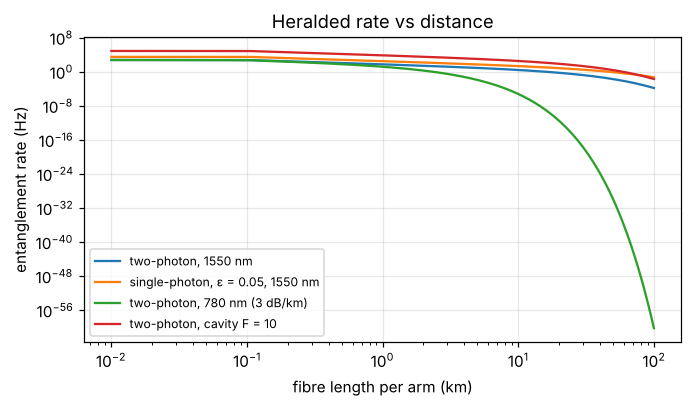

In [2]:
L = np.logspace(-2, 2, 200)
for lab, kw in (("two-photon, 1550 nm", {}), ("single-photon, ε = 0.05, 1550 nm", dict(scheme="single")),
                ("two-photon, 780 nm (3 dB/km)", dict(alpha_dB_km=3)), ("two-photon, cavity F = 10", dict(purcell=10))):
    plt.loglog(L, [link(L_km=l, **kw)["rate_Hz"] for l in L], label=lab)
plt.xlabel("fibre length per arm (km)"); plt.ylabel("entanglement rate (Hz)"); plt.legend(fontsize=8); plt.title("Heralded rate vs distance")

## 2. Two-photon interference
The heralding photons must be indistinguishable. With mode overlap M, the Hong–Ou–Mandel coincidence probability for a delay τ (in units of the photon coherence time) is $P_c = \tfrac12(1 - M e^{-|\tau|})$; the dip visibility is M, and the entangled-state fidelity falls with it.

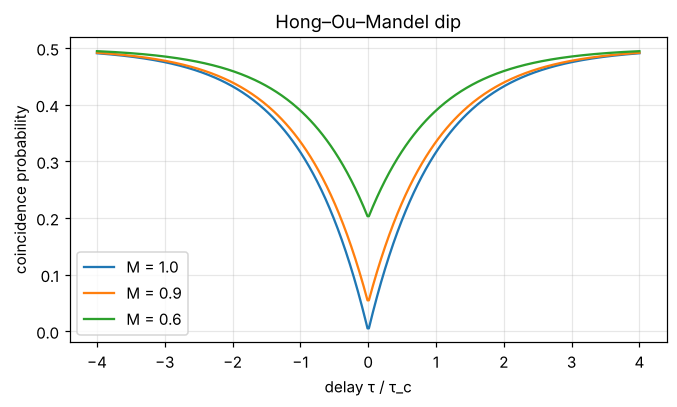

In [3]:
tau = np.linspace(-4, 4, 400)
for M in (1.0, 0.9, 0.6):
    plt.plot(tau, 0.5 * (1 - M * np.exp(-np.abs(tau))), label=f"M = {M}")
plt.xlabel("delay τ / τ_c"); plt.ylabel("coincidence probability"); plt.legend(); plt.title("Hong–Ou–Mandel dip")

The page goes on to entanglement distillation and a Monte Carlo quantum-repeater chain; those are best explored interactively there.

## 3. Check against the page

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

DECIMALS = dict(eta_coll_pct=2, T_pct=2, eta_pct=2, p_pct=2, rate_Hz=1, t_pair_ms=1)
page = dict(eta_coll_pct=6.70, T_pct=99.96, eta_pct=3.70, p_pct=0.07, rate_Hz=684.3, t_pair_ms=1.5)
check(r, page)

eta_coll_pct: notebook 6.699        page 6.7        OK
       T_pct: notebook 99.96        page 99.96      OK
     eta_pct: notebook 3.7          page 3.7        OK
       p_pct: notebook 0.06843      page 0.07       OK
     rate_Hz: notebook 684.3        page 684.3      OK
   t_pair_ms: notebook 1.461        page 1.5        OK
All values match the page.